# Experiment 4 — Strategic deconfliction between UAVs

Two UAVs propose perpendicular flight plans at the same altitude and would reach the intersection simultaneously. The experiment compares the scenario without SD and with recursive time-shift deconfliction.

In [7]:
from pathlib import Path

from IPython.display import Image, Markdown, display

from musas.airspace import Airspace
from musas.algorithms import (
    FirstOrderDynamics,
    MinimumSeparationConflictPrediction,
    RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from musas.simulation.metrics import calculate_metrics

OUTPUT_DIRECTORY = Path("outputs") / "output_4"
FIGURE_DIRECTORY = Path("figs") / "figs_4"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

## Parameters

| Component | Parameter | Value | Note |
|---|---|---:|---|
| Experiment | Cases | Without SD; With SD | Used |
| Experiment | Simulation end | 45.0 s | Used |
| Flight plans | Altitude | 100.0 m | Used |
| Flight plans | Start / arrival time | 2.0 / 22.0 s | Used |
| Flight plans | Nominal intersection time | 12.0 s | Used for snapshot |
| Flight plans | Priority | 0 for both UAVs | Default; tie resolved by FCFS order |
| UAV A | Route | $(-100,0)$ to $(100,0)$ m | Used |
| UAV B | Route | $(0,-100)$ to $(0,100)$ m | Used |
| Strategic CP | Algorithm | MinimumSeparationConflictPrediction | With-SD case only |
| Strategic CP | Minimum separation | 30.0 m | Used |
| Strategic CP | Sampling interval | 0.25 s | Used |
| Strategic deconfliction | Algorithm | RecursiveTimeShiftDeconfliction | With-SD case only |
| Strategic deconfliction | Time-shift step | 5.0 s | Used |
| Strategic deconfliction | Maximum time shifts | 20 | Default |
| Path planner | Lateral / vertical clearance | 10.0 / 10.0 m | Defaults; inactive without restrictions |
| Path planner | Maximum maneuvers | 4 | Default; inactive |
| Path planner | Lateral / vertical maneuvers | Enabled / enabled | Defaults; inactive |
| UAVs | Submission time | 0.0 s | Default |
| UAVs | Registration / FCFS order | UAV A, then UAV B | Used |
| UAVs | Waypoint acceptance radius | 1.0 m | Default |
| Dynamics | Velocity time constant / max. acceleration | 0.0 s / 100.0 m/s² | Used |
| Guidance | Minimum / maximum speed | 0.0 / 15.0 m/s | Default / used |
| Sensors | Sensor model | PerfectSensor | UAV default; reports inactive |
| Airspace | Obstacles, geofences and wind zones | None | Used |
| Simulation | Tactical deconfliction / tracking | Disabled / disabled | Defaults |
| Simulation | Network delay | 0.0 s | Default |
| Simulation | Flight-update interval | 0.1 s | Default |
| Simulation | Trajectory-record interval | 0.2 s | Default |
| Simulation | Report interval | 0.5 s | Default; inactive |
| Simulation | Collision distance | 1.0 m | Default |
| Simulation | Processing times | 0.0 s | Defaults |
| Dataset | Flush interval / keep history | 10.0 s / True | Defaults |
| Dataset | Overwrite existing file | True | Used |
| Network events | Message types logged | None | Used |
| Metrics | Minimum separation / collision distance | 30.0 / 1.0 m | Used |
| Visualization | View / conflict snapshot | XY / 12.0 s | Used |
| Visualization | Frame step | 0.25 s | Used |
| Visualization | Figure size / static DPI | $(8.0,5.5)$ in / 300 | Defaults |
| Visualization | Animation FPS / DPI | 10 / 120 | Used / default |
| Visualization | Plans, trajectories, positions, legend, grid | Shown | Used/default |
| Visualization | Tracks, reports and airspace layers | Hidden | Used |

In [8]:
SIMULATION_END = 45.0
CONFLICT_SNAPSHOT_TIME = 12.0
MINIMUM_SEPARATION_DISTANCE = 30.0
COLLISION_DISTANCE = 1.0

def create_flight_plans():
    return {
        "UAV A": FlightPlan([
            Waypoint(-100.0, 0.0, 100.0, 2.0),
            Waypoint(100.0, 0.0, 100.0, 22.0),
        ]),
        "UAV B": FlightPlan([
            Waypoint(0.0, -100.0, 100.0, 2.0),
            Waypoint(0.0, 100.0, 100.0, 22.0),
        ]),
    }

## Run both cases

UAV A is registered first. Under FCFS, its plan remains unchanged and UAV B receives the recursive time shift.

In [9]:
def run_case(case_name, use_sd):
    dataset_path = OUTPUT_DIRECTORY / f"{case_name}.sqlite"

    strategic_predictor = None
    strategic_deconfliction = None
    if use_sd:
        strategic_predictor = MinimumSeparationConflictPrediction(
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            sampling_interval=0.25,
        )
        strategic_deconfliction = RecursiveTimeShiftDeconfliction(
            conflict_prediction_algorithm=strategic_predictor,
            time_shift_step=5.0,
            maximum_time_shifts=20,
        )

    simulation = Simulation(
        airspace=Airspace(),
        strategic_conflict_prediction_algorithm=strategic_predictor,
        strategic_deconfliction_algorithm=strategic_deconfliction,
        message_types_to_log=(),
        dataset_path=dataset_path,
        dataset_metadata={"experiment": 4, "case": case_name},
        overwrite_dataset=True,
    )
    for uav_name, flight_plan in create_flight_plans().items():
        simulation.add_uav(
            name=uav_name,
            flight_plan=flight_plan,
            dynamics_algorithm=FirstOrderDynamics(
                max_acceleration=100.0,
                velocity_time_constant=0.0,
            ),
            guidance_algorithm=WaypointGuidance(
                min_speed=0.0,
                max_speed=15.0,
            ),
        )
    simulation.run(until=SIMULATION_END)
    simulation.close()
    return dataset_path

dataset_paths = {
    "Without SD": run_case("without_sd", use_sd=False),
    "With SD": run_case("with_sd", use_sd=True),
}
dataset_paths

{'Without SD': PosixPath('outputs/output_4/without_sd.sqlite'),
 'With SD': PosixPath('outputs/output_4/with_sd.sqlite')}

## Results

In [10]:
table = [
    "| Case | Final status | Strategic conflicts | Modified flights | "
    "Losses of separation | Collisions | Minimum separation | UAV B updates |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for case_name, dataset_path in dataset_paths.items():
    with SimulationDataset(dataset_path) as dataset:
        metrics = calculate_metrics(
            dataset,
            minimum_separation_distance=MINIMUM_SEPARATION_DISTANCE,
            collision_distance=COLLISION_DISTANCE,
        )
        statuses = ", ".join(
            f"{uav.name}: {uav.final_status}"
            for uav in dataset.get_uavs()
        )
    separation = metrics["minimum_pairwise_separation"]
    separation_text = "N/A" if separation is None else f"{separation:.2f}"
    table.append(
        f"| {case_name} | {statuses} | {metrics['detected_strategic_conflicts']} | "
        f"{metrics['modified_flights']} | {metrics['loss_of_separation_events']} | "
        f"{metrics['collision_events']} | {separation_text} | "
        f"{metrics['per_uav']['UAV B']['updates']} |"
    )
display(Markdown("\n".join(table)))

| Case | Final status | Strategic conflicts | Modified flights | Losses of separation | Collisions | Minimum separation | UAV B updates |
|---|---|---:|---:|---:|---:|---:|---:|
| Without SD | UAV A: COLLIDED, UAV B: COLLIDED | 0 | 0 | 1 | 1 | 0.00 | 0 |
| With SD | UAV A: COMPLETED, UAV B: COMPLETED | 1 | 1 | 0 | 0 | 35.80 | 1 |

## Conflict-time snapshots, final figures and animations

At $t=12$ s the original plans place both UAVs at the intersection. In the SD case, UAV B is delayed and remains separated from UAV A.

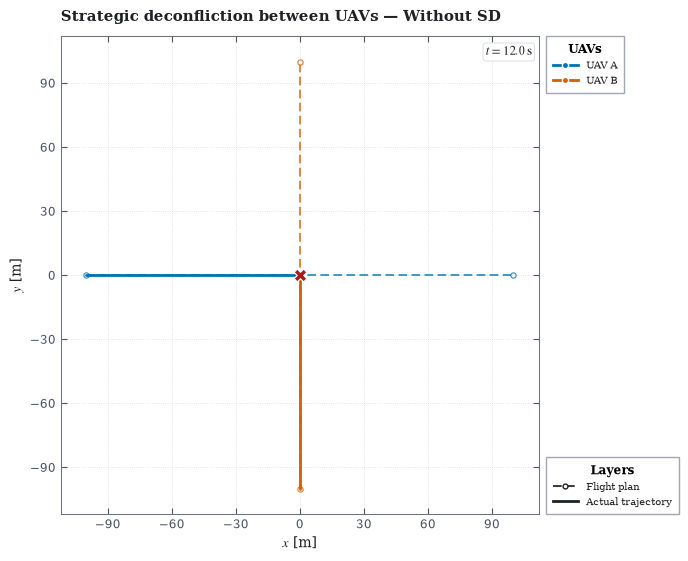

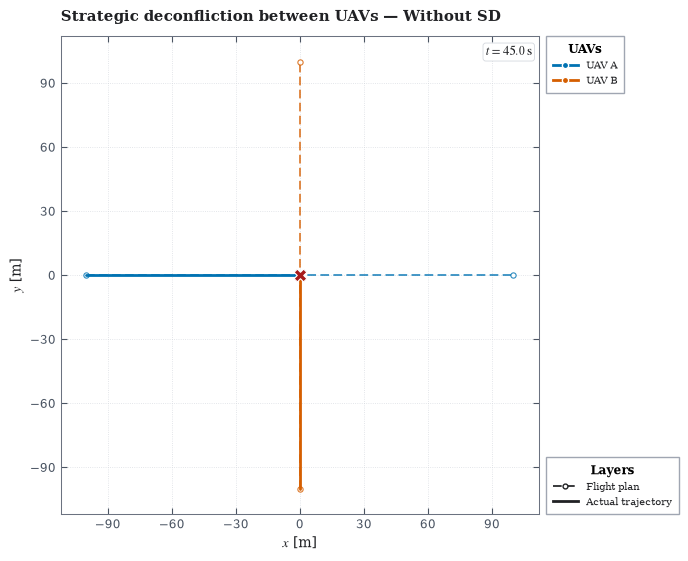

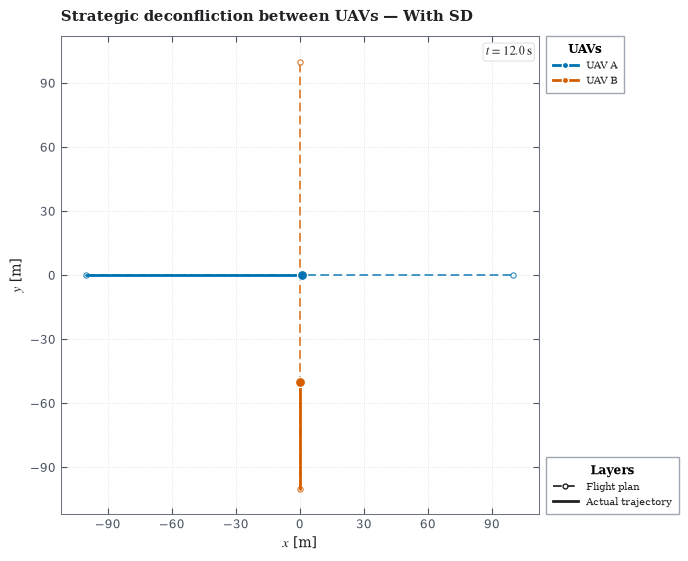

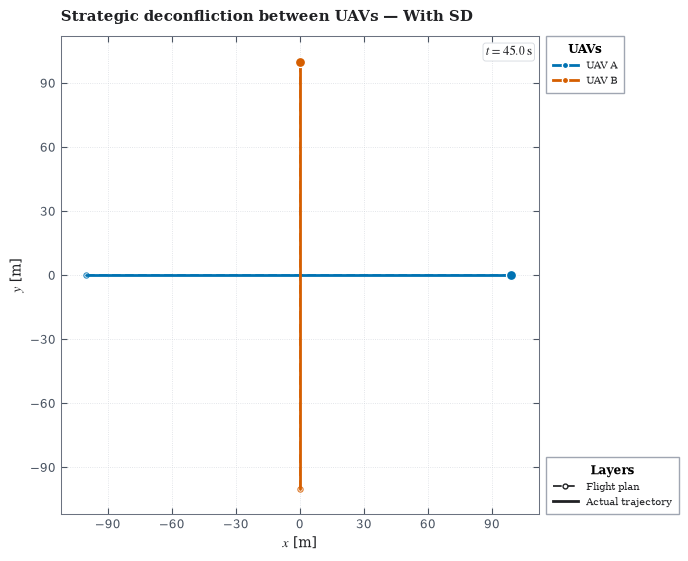

Figures: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/experiments/figs/figs_4


In [11]:
def visualization_config(case_name):
    return VisualizationConfig(
        uav_names=("UAV A", "UAV B"),
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_tracks=False,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_geofences=False,
        show_wind_zones=False,
        show_obstacles=False,
        frame_step=0.25,
        title=f"Strategic deconfliction between UAVs — {case_name}",
        spatial_unit="m",
    )

animation_paths = {}
for case_name, dataset_path in dataset_paths.items():
    file_label = case_name.lower().replace(" ", "_")
    config = visualization_config(case_name)
    conflict_figure = plot_dataset(
        dataset_path=dataset_path,
        config=config,
        timestamp=CONFLICT_SNAPSHOT_TIME,
        output_path=FIGURE_DIRECTORY / f"{file_label}_conflict_time.png",
    )
    display(conflict_figure)
    final_figure = plot_dataset(
        dataset_path=dataset_path,
        config=config,
        timestamp=SIMULATION_END,
        output_path=FIGURE_DIRECTORY / f"{file_label}_final.png",
    )
    display(final_figure)
    animation_path = FIGURE_DIRECTORY / f"{file_label}.gif"
    animate_dataset(
        dataset_path=dataset_path,
        config=config,
        output_path=animation_path,
        fps=10.0,
    )
    animation_paths[case_name] = animation_path

print("Figures:", FIGURE_DIRECTORY.resolve())

### Without SD

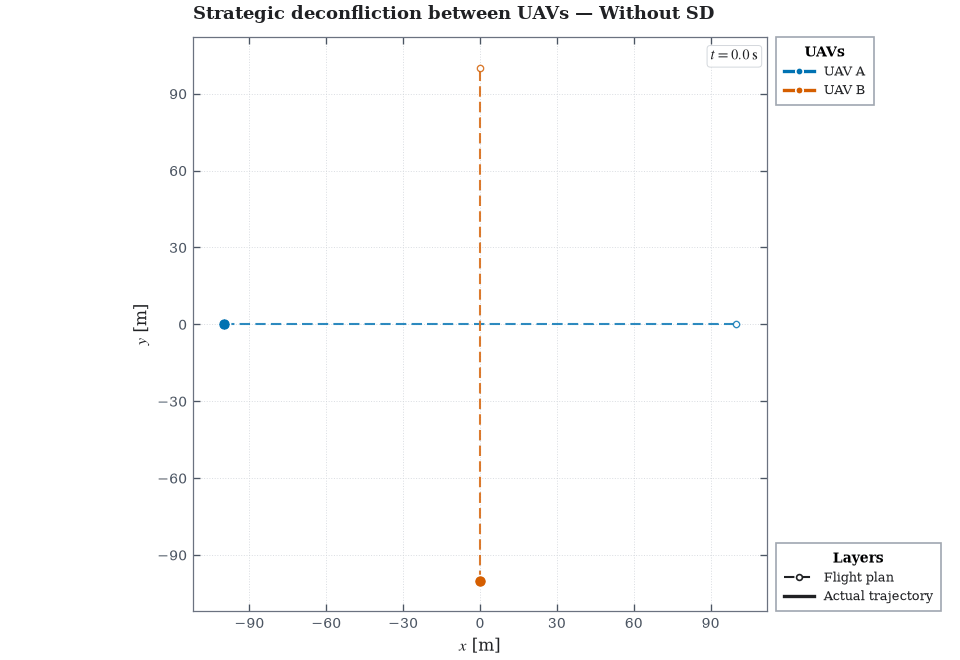

### With SD

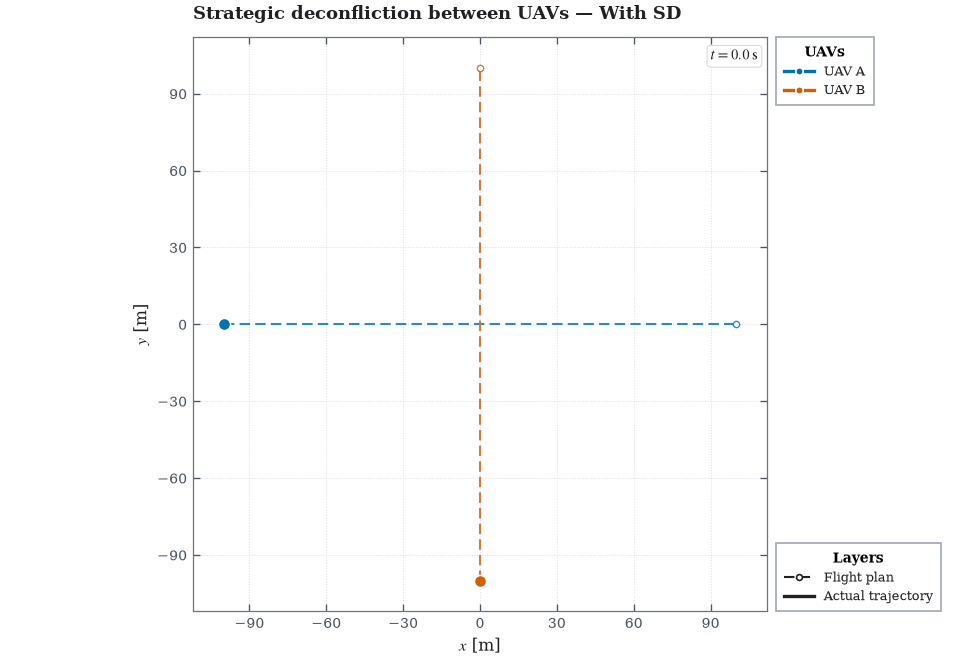

In [12]:
for case_name, animation_path in animation_paths.items():
    display(Markdown(f"### {case_name}"))
    display(Image(filename=animation_path))